# Palmer Penguins: wykresy rozrzutu

![Logo palmerpenguins z pingwinami Adelie, Chinstrap i Gentoo](https://allisonhorst.github.io/palmerpenguins/reference/figures/logo.png)

*Logo zbioru palmerpenguins, autorka: Allison Horst*

## 1. Wczytanie danych

Zbiór zawiera pomiary pingwinów z trzech gatunków (*Adelie*, *Chinstrap*, *Gentoo*), zebrane w latach 2007-2009
na trzech wyspach Antarktydy.

| Kolumna | Opis |
|---|---|
| `species` | gatunek |
| `island` | wyspa |
| `bill_length_mm` | długość dzioba [mm] |
| `bill_depth_mm` | wysokość dzioba [mm] |
| `flipper_length_mm` | długość płetwy [mm] |
| `body_mass_g` | masa ciała [g] |
| `sex` | płeć |
| `year` | rok pomiaru |
| `bill_ratio` | wskaźnik kształtu dzioba $w$ (liczony przy wczytaniu) |

Plik CSV wczytujemy funkcją `pd.read_csv()`, a wiersze z brakującymi wartościami usuwamy
metodą `dropna()`.

Dodatkowo liczymy **wskaźnik kształtu dzioba**, czyli ile razy dziób jest dłuższy niż wysoki:

$$
w = \frac{l}{h}
$$

gdzie $l$ to długość dzioba (`bill_length_mm`), a $h$ jego wysokość (`bill_depth_mm`). Krótki i wysoki dziób
(*Adelie*) ma wskaźnik około 2, a długi i smukły (*Gentoo*) ponad 3.

In [26]:
import pandas as pd

URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(URL).dropna()
df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]  # wskaźnik w = l / h
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_ratio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,2.238889
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,1.901554
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007,1.907767
...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009,2.818182
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009,2.403315
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009,2.725275
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009,2.673684


## 2. Wykres rozrzutu w matplotlib

Wykres rozrzutu pokazuje, czy dwie cechy są ze sobą powiązane. Tutaj zestawiamy długość płetwy z masą ciała:
im dłuższa płetwa, tym zwykle cięższy pingwin.

W [matplotlib](https://matplotlib.org/) każdy gatunek rysujemy osobno funkcją `plt.scatter()`, żeby dostać legendę.

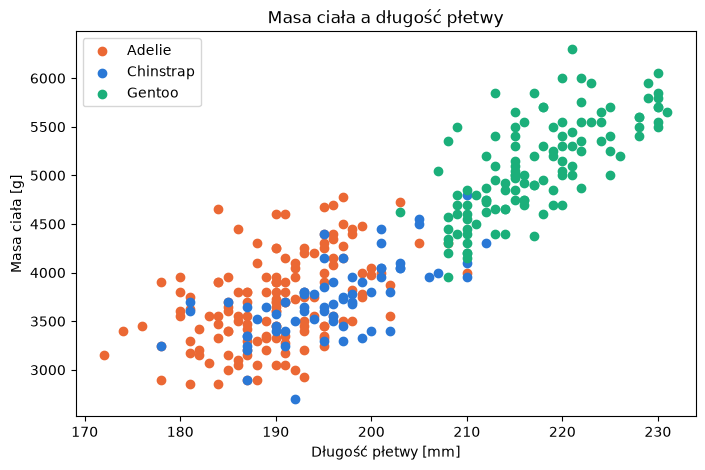

In [27]:
import matplotlib.pyplot as plt

COLORS = {"Adelie": "#eb6834", "Chinstrap": "#2a78d6", "Gentoo": "#1baf7a"}

plt.figure(figsize=(8, 5))
for species, group in df.groupby("species"):
    plt.scatter(group["flipper_length_mm"], group["body_mass_g"], label=species, color=COLORS[species])
plt.xlabel("Długość płetwy [mm]")
plt.ylabel("Masa ciała [g]")
plt.title("Masa ciała a długość płetwy")
plt.legend()
plt.show()

## 3. Wykres rozrzutu w plotly

Ten sam wykres w [plotly](https://plotly.com/python/) jest interaktywny: po najechaniu na punkt widać jego wartości,
obszar można przybliżyć, a kliknięcie gatunku w legendzie go ukrywa. Wystarczy jedno wywołanie `px.scatter()`.

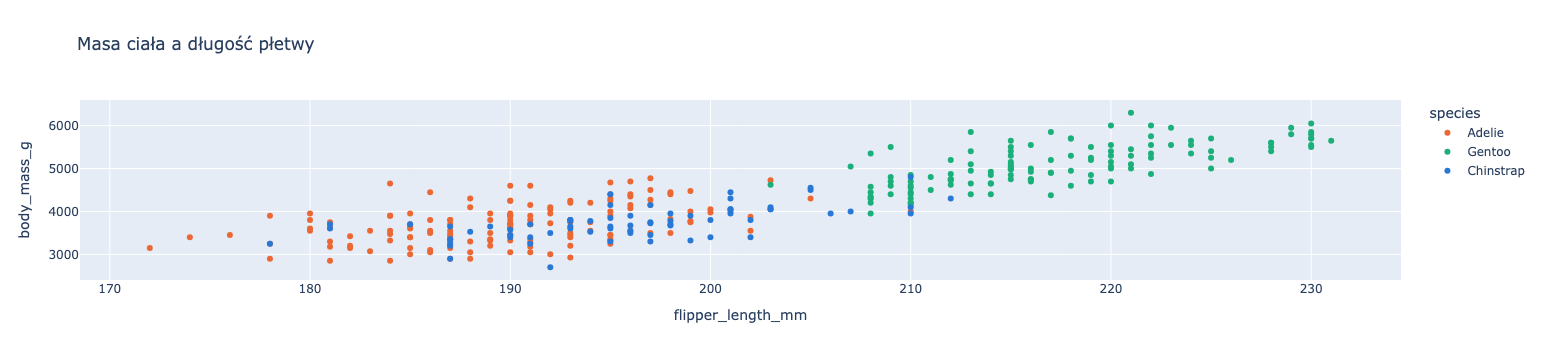

In [28]:
import plotly.express as px

fig = px.scatter(df, x="flipper_length_mm", y="body_mass_g", color="species", color_discrete_map=COLORS,
                 title="Masa ciała a długość płetwy")
fig.show()

## 4. Interaktywny interfejs

Dekorator `@interact` z biblioteki [ipywidgets](https://ipywidgets.readthedocs.io/en/stable/) tworzy kontrolki
z argumentów funkcji i wywołuje ją ponownie przy każdej zmianie:

```python
@interact(x=Dropdown(options=["a", "b"]))
def plot(x):
    ...  # rysuje wykres dla wybranej wartości x
```

Listy rozwijane wybierają cechy na osiach, a pola wyboru określają, które gatunki są widoczne na wykresie.
Na liście jest też wskaźnik `bill_ratio`: po ustawieniu go na jednej z osi gatunki wyraźnie się rozdzielają.

In [29]:
from ipywidgets import interact, Dropdown, Checkbox

NUMERIC = ["bill_length_mm", "bill_depth_mm", "bill_ratio", "flipper_length_mm", "body_mass_g"]

@interact(
    x=Dropdown(options=NUMERIC, value="bill_length_mm", description="Oś X"),
    y=Dropdown(options=NUMERIC, value="bill_depth_mm", description="Oś Y"),
    adelie=Checkbox(value=True, description="Adelie"),
    chinstrap=Checkbox(value=True, description="Chinstrap"),
    gentoo=Checkbox(value=True, description="Gentoo"),
)
def plot(x, y, adelie, chinstrap, gentoo):
    selected = {"Adelie": adelie, "Chinstrap": chinstrap, "Gentoo": gentoo}
    data = df[df["species"].map(selected)]

    plt.figure(figsize=(8, 5))
    for species, group in data.groupby("species"):
        plt.scatter(group[x], group[y], label=species, color=COLORS[species])
    plt.xlabel(x)
    plt.ylabel(y)
    plt.legend()
    plt.show()

interactive(children=(Dropdown(description='Oś X', options=('bill_length_mm', 'bill_depth_mm', 'bill_ratio', '…

## Źródła

- Dane: A.M. Horst, A.P. Hill, K.B. Gorman (2020), [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/);
  kopia na [Kaggle](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data).
- Ilustracja pingwinów: Allison Horst.